In [1]:
!pip install -q kagglehub scikit-image

import os, random, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from tqdm.notebook import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
print("Ready")

Ready


In [2]:
import zipfile

zip_path = "/content/flowers_cleaned.zip"
extract_path = "/content/flowers_cleaned"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction completed!")

Extraction completed!


In [3]:
# Folder with 200 clean images per class (one sub-folder per class)
cleaned_path = "/content/flowers_cleaned"   # change this if your folder is elsewhere

for c in sorted(os.listdir(cleaned_path)):
    print(c, len(os.listdir(os.path.join(cleaned_path, c))))

daisy 200
dandelion 200
rose 200
sunflower 200
tulip 200


# Resizing and Normalization

In [4]:
IMG_SIZE = 64

X = []
y = []

for class_name in sorted(os.listdir(cleaned_path)):
    class_path = os.path.join(cleaned_path, class_name)
    for image_name in tqdm(sorted(os.listdir(class_path)), desc=class_name):
        img = Image.open(os.path.join(class_path, image_name)).convert("RGB")
        # center-crop to a square (keeps the aspect ratio), then resize
        img = ImageOps.fit(img, (IMG_SIZE, IMG_SIZE), Image.Resampling.LANCZOS)
        X.append(np.array(img))
        y.append(class_name)

X = np.array(X, dtype=np.float32) / 255.0   # normalize to [0, 1]
y = np.array(y)
CLASSES = sorted(np.unique(y))

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Pixel range:", X.min(), "to", X.max())
print("Classes:", CLASSES)

daisy:   0%|          | 0/200 [00:00<?, ?it/s]

dandelion:   0%|          | 0/200 [00:00<?, ?it/s]

rose:   0%|          | 0/200 [00:00<?, ?it/s]

sunflower:   0%|          | 0/200 [00:00<?, ?it/s]

tulip:   0%|          | 0/200 [00:00<?, ?it/s]

X shape: (1000, 64, 64, 3)
y shape: (1000,)
Pixel range: 0.0 to 1.0
Classes: [np.str_('daisy'), np.str_('dandelion'), np.str_('rose'), np.str_('sunflower'), np.str_('tulip')]


# Spliting

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp)

print("Train:", X_train.shape)
print("Val:  ", X_val.shape)
print("Test: ", X_test.shape)

Train: (700, 64, 64, 3)
Val:   (150, 64, 64, 3)
Test:  (150, 64, 64, 3)


# Raw pixels

In [6]:
# Raw pixels: flatten each 64x64x3 image into one vector
X_train_raw = X_train.reshape(len(X_train), -1)
X_val_raw   = X_val.reshape(len(X_val), -1)
X_test_raw  = X_test.reshape(len(X_test), -1)

print("Raw train:", X_train_raw.shape)
print("Raw val:  ", X_val_raw.shape)
print("Raw test: ", X_test_raw.shape)

Raw train: (700, 12288)
Raw val:   (150, 12288)
Raw test:  (150, 12288)


# HOG 8X8

In [7]:
from skimage.feature import hog

def extract_hog(imgs):
    return np.array([
        hog(img, orientations=9, pixels_per_cell=(8, 8),
            cells_per_block=(2, 2), channel_axis=-1)
        for img in imgs
    ])

X_train_hog = extract_hog(X_train)
X_val_hog   = extract_hog(X_val)
X_test_hog  = extract_hog(X_test)

print("HOG train:", X_train_hog.shape)
print("HOG val:  ", X_val_hog.shape)
print("HOG test: ", X_test_hog.shape)

HOG train: (700, 1764)
HOG val:   (150, 1764)
HOG test:  (150, 1764)


# HOG 16X16

In [8]:
def extract_hog16(imgs):
    return np.array([
        hog(img, orientations=9, pixels_per_cell=(16, 16),
            cells_per_block=(2, 2), channel_axis=-1)
        for img in imgs
    ])

X_train_hog16 = extract_hog16(X_train)
X_val_hog16   = extract_hog16(X_val)
X_test_hog16  = extract_hog16(X_test)

print("HOG-16 train:", X_train_hog16.shape)
print("HOG-16 val:  ", X_val_hog16.shape)
print("HOG-16 test: ", X_test_hog16.shape)

HOG-16 train: (700, 324)
HOG-16 val:   (150, 324)
HOG-16 test:  (150, 324)


# Color Histogram

In [9]:
from skimage.color import rgb2hsv

def extract_hsv_hist(imgs, bins=(12, 4, 4)):
    feats = []
    for img in imgs:
        hsv = rgb2hsv(img).reshape(-1, 3)
        # joint histogram: 12 hue x 4 saturation x 4 value bins
        h, _ = np.histogramdd(hsv, bins=bins, range=[(0, 1)] * 3)
        h = h.ravel()
        feats.append(np.sqrt(h / h.sum()))   # normalize, then sqrt (Hellinger)
    return np.array(feats)

X_train_color = extract_hsv_hist(X_train)
X_val_color   = extract_hsv_hist(X_val)
X_test_color  = extract_hsv_hist(X_test)

print("Color train:", X_train_color.shape)
print("Color val:  ", X_val_color.shape)
print("Color test: ", X_test_color.shape)

Color train: (700, 192)
Color val:   (150, 192)
Color test:  (150, 192)


# PCA

In [10]:
from sklearn.decomposition import PCA

# Learn the components from the TRAIN set only, then apply them to val and test
pca = PCA(n_components=100, random_state=SEED)

X_train_pca = pca.fit_transform(X_train_raw)
X_val_pca   = pca.transform(X_val_raw)
X_test_pca  = pca.transform(X_test_raw)

print("PCA train:", X_train_pca.shape)
print("PCA val:  ", X_val_pca.shape)
print("PCA test: ", X_test_pca.shape)
print("Explained variance kept:", round(pca.explained_variance_ratio_.sum(), 4))

PCA train: (700, 100)
PCA val:   (150, 100)
PCA test:  (150, 100)
Explained variance kept: 0.8158


# StandardScaler + Logistic Regression MODEL

In [11]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.metrics import accuracy_score

# Build L2-normalized Color + weighted HOG16 (w_hog = 0.8) for train and val
w_hog = 0.8
col_tr_l2 = normalize(X_train_color, norm="l2")
col_va_l2 = normalize(X_val_color,   norm="l2")
hog_tr_l2 = normalize(X_train_hog16, norm="l2")
hog_va_l2 = normalize(X_val_hog16,   norm="l2")

Xtr_color_hog16_w08 = np.hstack([col_tr_l2, w_hog * hog_tr_l2])
Xv_color_hog16_w08  = np.hstack([col_va_l2, w_hog * hog_va_l2])

# Feature sets: keep all original sets intact and include the weighted L2 fusion set
feature_sets = {
    "Raw":                (X_train_raw,         X_val_raw,         True),
    "HOG-8":              (X_train_hog,         X_val_hog,         False),
    "HOG-16":             (X_train_hog16,       X_val_hog16,       False),
    "Color":              (X_train_color,       X_val_color,       False),
    "PCA":                (X_train_pca,         X_val_pca,         False),
    "Color+HOG16(w=0.8)": (Xtr_color_hog16_w08, Xv_color_hog16_w08, False),
}

C_values = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000]

lr_results = {}

for name, (Xtr, Xv, use_scaler) in feature_sets.items():
    scaler = None
    if use_scaler:
        scaler = StandardScaler().fit(Xtr)      # fit on TRAIN only
        Xtr, Xv = scaler.transform(Xtr), scaler.transform(Xv)

    best = None
    print(f"\n--- {name} ---")
    for C in C_values:
        model = LogisticRegression(C=C, max_iter=3000)
        model.fit(Xtr, y_train)
        train_acc = model.score(Xtr, y_train)
        val_acc = model.score(Xv, y_val)
        print(f"C={C:<8} train={train_acc:.4f}  val={val_acc:.4f}")
        if best is None or val_acc > best["val_acc"]:     # first best wins ties
            best = dict(C=C, val_acc=val_acc, train_acc=train_acc, model=model, scaler=scaler)
    lr_results[name] = best

print("\n===== Best Logistic Regression per feature set (chosen on validation) =====")
summary = pd.DataFrame([
    {"Features": n, "Best C": r["C"], "Train acc": r["train_acc"], "Val acc": r["val_acc"]}
    for n, r in lr_results.items()
]).sort_values("Val acc", ascending=False)
print(summary.round(4).to_string(index=False))


--- Raw ---
C=0.0001   train=0.6886  val=0.4600
C=0.001    train=0.9471  val=0.4600
C=0.01     train=1.0000  val=0.4067
C=0.1      train=1.0000  val=0.3733
C=1        train=1.0000  val=0.3667
C=10       train=1.0000  val=0.4000
C=100      train=1.0000  val=0.3533
C=1000     train=1.0000  val=0.3533

--- HOG-8 ---
C=0.0001   train=0.5171  val=0.4267
C=0.001    train=0.5243  val=0.4200
C=0.01     train=0.5814  val=0.4400
C=0.1      train=0.8086  val=0.4467
C=1        train=0.9957  val=0.4267
C=10       train=1.0000  val=0.4200
C=100      train=1.0000  val=0.4267
C=1000     train=1.0000  val=0.4133

--- HOG-16 ---
C=0.0001   train=0.4486  val=0.4533
C=0.001    train=0.4586  val=0.4400
C=0.01     train=0.4771  val=0.4533
C=0.1      train=0.5157  val=0.4467
C=1        train=0.6086  val=0.4400
C=10       train=0.7057  val=0.4400
C=100      train=0.8571  val=0.3467
C=1000     train=0.9900  val=0.3533

--- Color ---
C=0.0001   train=0.5057  val=0.5067
C=0.001    train=0.5400  val=0.5200
C=0.0

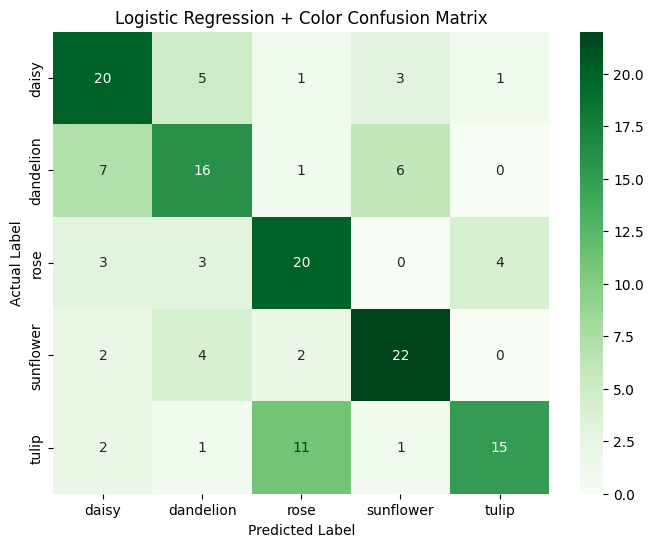

              precision    recall  f1-score   support

       daisy       0.59      0.67      0.62        30
   dandelion       0.55      0.53      0.54        30
        rose       0.57      0.67      0.62        30
   sunflower       0.69      0.73      0.71        30
       tulip       0.75      0.50      0.60        30

    accuracy                           0.62       150
   macro avg       0.63      0.62      0.62       150
weighted avg       0.63      0.62      0.62       150



In [12]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# Get best Logistic Regression model
best_lr = lr_results["Color"]["model"]
class_names = ["daisy", "dandelion", "rose", "sunflower", "tulip"]
# Predict validation data
y_pred_lr = best_lr.predict(X_val_color)

# Confusion Matrix
cm = confusion_matrix(y_val, y_pred_lr, labels=class_names)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Logistic Regression + Color Confusion Matrix")
plt.show()

print(classification_report(y_val, y_pred_lr, labels=class_names))

# KNN

In [13]:
#
import numpy as np
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler, normalize

# Build L2-normalized Color + weighted HOG16 feature set (w_hog = 0.8)
w_hog = 0.8
col_tr_l2 = normalize(X_train_color, norm="l2")
col_va_l2 = normalize(X_val_color, norm="l2")
hog_tr_l2 = normalize(X_train_hog16, norm="l2")
hog_va_l2 = normalize(X_val_hog16, norm="l2")

Xtr_color_hog16_w08 = np.hstack([col_tr_l2, w_hog * hog_tr_l2])
Xv_color_hog16_w08  = np.hstack([col_va_l2, w_hog * hog_va_l2])

# Add the weighted fusion set to feature_sets without re-scaling pre-normalized vectors
enhanced_feature_sets = dict(feature_sets)
enhanced_feature_sets["Color+HOG16(w=0.8)"] = (Xtr_color_hog16_w08, Xv_color_hog16_w08, False)

k_values = [3, 5, 7, 9, 11, 15, 21]
weights_options = ["uniform", "distance"]
metric_options = ["euclidean", "cosine"]

knn_results = {}

for name, (Xtr, Xv, use_scaler) in enhanced_feature_sets.items():
    scaler = None
    if use_scaler:
        scaler = StandardScaler().fit(Xtr)      # fit on TRAIN only
        Xtr, Xv = scaler.transform(Xtr), scaler.transform(Xv)

    # Use the tuned parameters (k=7, weights='distance', metric='cosine') for the weighted fusion set
    if name == "Color+HOG16(w=0.8)":
        model = KNeighborsClassifier(n_neighbors=7, weights="distance", metric="cosine")
        model.fit(Xtr, y_train)
        best = {
            "k": 7,
            "weights": "distance",
            "metric": "cosine",
            "val_acc": model.score(Xv, y_val),
            "train_acc": model.score(Xtr, y_train),
            "model": model,
            "scaler": scaler,
        }
    else:
        best = None
        for metric in metric_options:
            for weights in weights_options:
                for k in k_values:
                    model = KNeighborsClassifier(n_neighbors=k, weights=weights, metric=metric)
                    model.fit(Xtr, y_train)
                    val_acc = model.score(Xv, y_val)
                    if best is None or val_acc > best["val_acc"]:     # first best wins ties
                        best = dict(
                            k=k,
                            weights=weights,
                            metric=metric,
                            val_acc=val_acc,
                            train_acc=model.score(Xtr, y_train),
                            model=model,
                            scaler=scaler,
                        )

    knn_results[name] = best
    print(
        f"{name:20s} best k={best['k']:<3} weights={best['weights']:<9} metric={best['metric']:<10} "
        f"train={best['train_acc']:.4f} val={best['val_acc']:.4f}"
    )

print("\n===== Best KNN per feature set (chosen on validation) =====")
knn_summary = pd.DataFrame([
    {
        "Features": n,
        "k": r["k"],
        "weights": r["weights"],
        "metric": r["metric"],
        "Train acc": r["train_acc"],
        "Val acc": r["val_acc"],
    }
    for n, r in knn_results.items()
]).sort_values("Val acc", ascending=False)

print(knn_summary.round(4).to_string(index=False))

Raw                  best k=21  weights=distance  metric=cosine     train=1.0000 val=0.4467
HOG-8                best k=9   weights=uniform   metric=euclidean  train=0.4686 val=0.3333
HOG-16               best k=11  weights=distance  metric=euclidean  train=1.0000 val=0.4000
Color                best k=9   weights=distance  metric=cosine     train=1.0000 val=0.6533
PCA                  best k=21  weights=distance  metric=cosine     train=1.0000 val=0.4600
Color+HOG16(w=0.8)   best k=7   weights=distance  metric=cosine     train=1.0000 val=0.6800

===== Best KNN per feature set (chosen on validation) =====
          Features  k  weights    metric  Train acc  Val acc
Color+HOG16(w=0.8)  7 distance    cosine     1.0000   0.6800
             Color  9 distance    cosine     1.0000   0.6533
               PCA 21 distance    cosine     1.0000   0.4600
               Raw 21 distance    cosine     1.0000   0.4467
            HOG-16 11 distance euclidean     1.0000   0.4000
             HOG-8  9

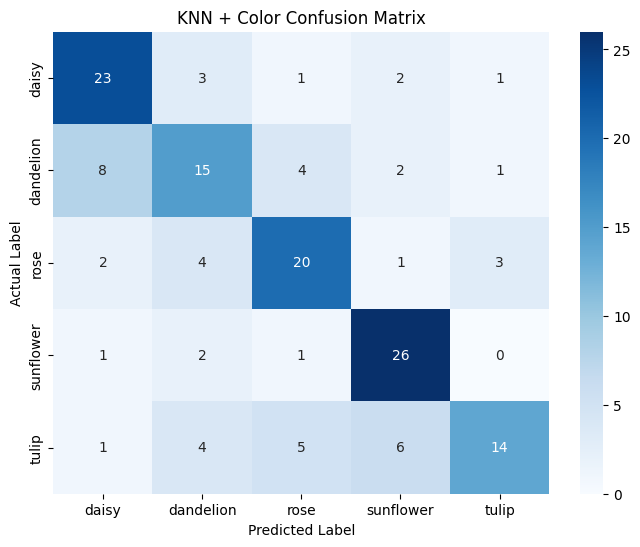

              precision    recall  f1-score   support

       daisy       0.66      0.77      0.71        30
   dandelion       0.54      0.50      0.52        30
        rose       0.65      0.67      0.66        30
   sunflower       0.70      0.87      0.78        30
       tulip       0.74      0.47      0.57        30

    accuracy                           0.65       150
   macro avg       0.66      0.65      0.65       150
weighted avg       0.66      0.65      0.65       150



In [14]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Get best KNN model
best_knn = knn_results["Color"]["model"]

# Predict validation data
y_pred_knn = best_knn.predict(X_val_color)

# Confusion Matrix
class_names = sorted(np.unique(y_train))

cm = confusion_matrix(y_val, y_pred_knn, labels=class_names)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("KNN + Color Confusion Matrix")
plt.show()

print(classification_report(y_val, y_pred_knn, labels=class_names))

# K means

In [15]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.metrics import accuracy_score, silhouette_score


def fuse_l2_weighted(color_feat, hog_feat, w_hog=0.8):
    return np.hstack([
        normalize(color_feat, norm="l2"),
        w_hog * normalize(hog_feat, norm="l2"),
    ])


def majority_map(cluster_ids, labels, k):
    mapping = {}
    for c in range(k):
        mask = cluster_ids == c
        if np.any(mask):
            vals, counts = np.unique(labels[mask], return_counts=True)
            mapping[c] = vals[np.argmax(counts)]
        else:
            mapping[c] = labels[0]
    return mapping


K = 5  # one cluster per expected class

Xtr_km_l2 = fuse_l2_weighted(X_train_color, X_train_hog16, w_hog=0.8)
Xv_km_l2  = fuse_l2_weighted(X_val_color,   X_val_hog16,   w_hog=0.8)

km_feature_sets = {
    **{name: feature_sets[name] for name in ["Raw", "PCA", "HOG-8", "HOG-16", "Color"]},
    "Color+HOG16(L2)": (Xtr_km_l2, Xv_km_l2, False),
}

km_results = {}
for name, (Xtr, Xv, use_scaler) in km_feature_sets.items():
    scaler = None
    if use_scaler:
        scaler = StandardScaler().fit(Xtr)          # fit on TRAIN only
        Xtr, Xv = scaler.transform(Xtr), scaler.transform(Xv)

    km = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(Xtr)
    mapping = majority_map(km.labels_, y_train, K)

    val_clusters = km.predict(Xv)
    val_pred = np.array([mapping[c] for c in val_clusters])
    train_pred = np.array([mapping[c] for c in km.labels_])

    km_results[name] = dict(
        val_acc=accuracy_score(y_val, val_pred),
        train_acc=accuracy_score(y_train, train_pred),
        silhouette_val=silhouette_score(Xv, val_clusters),
        model=km,
        mapping=mapping,
        scaler=scaler,
    )
    print(
        f"{name:16s} train acc={km_results[name]['train_acc']:.4f}  "
        f"val acc={km_results[name]['val_acc']:.4f}  "
        f"silhouette(val)={km_results[name]['silhouette_val']:.4f}"
    )

km_summary = pd.DataFrame([
    {
        "Features": n,
        "Train acc": r["train_acc"],
        "Val acc (mapped)": r["val_acc"],
        "Silhouette (val)": r["silhouette_val"],
    }
    for n, r in km_results.items()
]).sort_values("Val acc (mapped)", ascending=False)

print("\n===== K-Means (K=5), chosen on validation =====")
print(km_summary.round(4).to_string(index=False))

Raw              train acc=0.2957  val acc=0.2800  silhouette(val)=0.0617
PCA              train acc=0.3071  val acc=0.3133  silhouette(val)=0.0911
HOG-8            train acc=0.3057  val acc=0.3267  silhouette(val)=0.0180
HOG-16           train acc=0.3086  val acc=0.2867  silhouette(val)=0.0325
Color            train acc=0.4171  val acc=0.3667  silhouette(val)=0.0688
Color+HOG16(L2)  train acc=0.3929  val acc=0.4600  silhouette(val)=0.0644

===== K-Means (K=5), chosen on validation =====
       Features  Train acc  Val acc (mapped)  Silhouette (val)
Color+HOG16(L2)     0.3929            0.4600            0.0644
          Color     0.4171            0.3667            0.0688
          HOG-8     0.3057            0.3267            0.0180
            PCA     0.3071            0.3133            0.0911
         HOG-16     0.3086            0.2867            0.0325
            Raw     0.2957            0.2800            0.0617


# Test Logistic Regression

Test Accuracy (Logistic Regression): 0.6467

Per-Class Metrics (Test - Logistic Regression):
    Class  Precision  Recall  F1-score  Support
    daisy     0.6061  0.6667    0.6349       30
dandelion     0.6429  0.6000    0.6207       30
     rose     0.6154  0.5333    0.5714       30
sunflower     0.6667  0.7333    0.6984       30
    tulip     0.7000  0.7000    0.7000       30


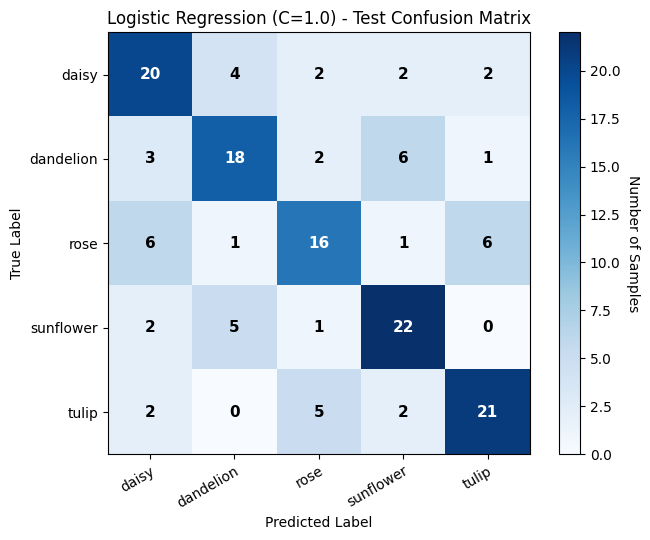

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import normalize
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_recall_fscore_support,
)


def fuse_l2_weighted(color_feat, hog_feat, w_hog=0.8):
    return np.hstack([
        normalize(color_feat, norm="l2"),
        w_hog * normalize(hog_feat, norm="l2"),
    ])


def plot_cm_heatmap(cm, labels, title):
    fig, ax = plt.subplots(figsize=(7, 5.5))
    im = ax.imshow(cm, interpolation="nearest", cmap="Blues")
    cbar = ax.figure.colorbar(im, ax=ax)
    cbar.ax.set_ylabel("Number of Samples", rotation=-90, va="bottom")

    ax.set(
        xticks=np.arange(len(labels)),
        yticks=np.arange(len(labels)),
        xticklabels=labels,
        yticklabels=labels,
        xlabel="Predicted Label",
        ylabel="True Label",
        title=title,
    )
    plt.setp(ax.get_xticklabels(), rotation=30, ha="right", rotation_mode="anchor")

    thresh = cm.max() / 2.0
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(
                j,
                i,
                format(cm[i, j], "d"),
                ha="center",
                va="center",
                color="white" if cm[i, j] > thresh else "black",
                fontsize=11,
                fontweight="bold",
            )

    fig.tight_layout()
    plt.show()


# 1) Prepare features & fit best Logistic Regression on train split only
Xtr_lr = fuse_l2_weighted(X_train_color, X_train_hog16, w_hog=0.8)
Xte_lr = fuse_l2_weighted(X_test_color,  X_test_hog16,  w_hog=0.8)

lr_model = LogisticRegression(C=1.0, max_iter=5000, random_state=SEED)
lr_model.fit(Xtr_lr, y_train)

# 2) Predict and report overall accuracy + per-class metrics on test set
y_test_pred_lr = lr_model.predict(Xte_lr)
print(f"Test Accuracy (Logistic Regression): {accuracy_score(y_test, y_test_pred_lr):.4f}\n")

labels = np.unique(y_test)
precision, recall, f1, support = precision_recall_fscore_support(
    y_test, y_test_pred_lr, labels=labels, zero_division=0
)
per_class_lr_df = pd.DataFrame({
    "Class": labels,
    "Precision": np.round(precision, 4),
    "Recall": np.round(recall, 4),
    "F1-score": np.round(f1, 4),
    "Support": support,
})
print("Per-Class Metrics (Test - Logistic Regression):")
print(per_class_lr_df.to_string(index=False))

# 3) Plot Confusion Matrix Heatmap
cm_lr = confusion_matrix(y_test, y_test_pred_lr, labels=labels)
plot_cm_heatmap(cm_lr, labels, "Logistic Regression (C=1.0) - Test Confusion Matrix")

# KNN test

Selected KNN: Color+HOG16(w=0.8) (k=7, weights='distance', metric='cosine')
Test Accuracy: 0.5333

    Class  Precision  Recall  F1-score  Support
    daisy     0.4878  0.6667    0.5634       30
dandelion     0.3462  0.3000    0.3214       30
     rose     0.5769  0.5000    0.5357       30
sunflower     0.6757  0.8333    0.7463       30
    tulip     0.5500  0.3667    0.4400       30


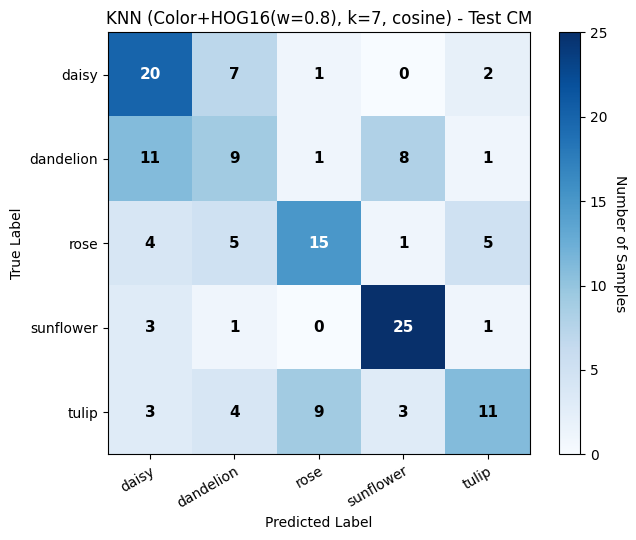

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_recall_fscore_support,
)

# 1) Select best KNN entry from knn_results (highest validation accuracy; Color+HOG16(w=0.8) is 0.6800)
best_knn_name = max(knn_results, key=lambda k: knn_results[k]["val_acc"])
best_knn_entry = knn_results[best_knn_name]
best_knn_model = best_knn_entry["model"]
best_knn_scaler = best_knn_entry["scaler"]

# Build X_test matching the selected feature representation
w_hog = 0.8
col_te_l2 = normalize(X_test_color, norm="l2")
hog_te_l2 = normalize(X_test_hog16, norm="l2")

test_knn_map = {
    "Color+HOG16(w=0.8)": np.hstack([col_te_l2, w_hog * hog_te_l2]),
    "Raw":    X_test_raw,
    "HOG-8":  X_test_hog,
    "HOG-16": X_test_hog16,
    "Color":  X_test_color,
    "PCA":    X_test_pca,
}

Xte_knn = test_knn_map[best_knn_name]
if best_knn_scaler is not None:
    Xte_knn = best_knn_scaler.transform(Xte_knn)

# 2) Predict on test set and print accuracy
y_test_pred_knn = best_knn_model.predict(Xte_knn)
print(
    f"Selected KNN: {best_knn_name} "
    f"(k={best_knn_entry['k']}, weights='{best_knn_entry['weights']}', metric='{best_knn_entry['metric']}')"
)
print(f"Test Accuracy: {accuracy_score(y_test, y_test_pred_knn):.4f}\n")

# 3) Per-class Precision, Recall, and F1-score
labels = np.unique(y_test)
precision, recall, f1, support = precision_recall_fscore_support(
    y_test, y_test_pred_knn, labels=labels, zero_division=0
)
per_class_knn_df = pd.DataFrame({
    "Class": labels,
    "Precision": np.round(precision, 4),
    "Recall": np.round(recall, 4),
    "F1-score": np.round(f1, 4),
    "Support": support,
})
print(per_class_knn_df.to_string(index=False))

# 4) Confusion Matrix Heatmap on Test
cm_knn = confusion_matrix(y_test, y_test_pred_knn, labels=labels)
fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(cm_knn, interpolation="nearest", cmap="Blues")
cbar = ax.figure.colorbar(im, ax=ax)
cbar.ax.set_ylabel("Number of Samples", rotation=-90, va="bottom")

ax.set(
    xticks=np.arange(len(labels)),
    yticks=np.arange(len(labels)),
    xticklabels=labels,
    yticklabels=labels,
    xlabel="Predicted Label",
    ylabel="True Label",
    title=f"KNN ({best_knn_name}, k={best_knn_entry['k']}, {best_knn_entry['metric']}) - Test CM",
)
plt.setp(ax.get_xticklabels(), rotation=30, ha="right", rotation_mode="anchor")

thresh = cm_knn.max() / 2.0
for i in range(cm_knn.shape[0]):
    for j in range(cm_knn.shape[1]):
        ax.text(
            j, i, format(cm_knn[i, j], "d"),
            ha="center", va="center",
            color="white" if cm_knn[i, j] > thresh else "black",
            fontsize=11, fontweight="bold",
        )

fig.tight_layout()
plt.show()

# K-Mean Test

Selected K-Means Features: Color+HOG16(L2) (K=5)
Test Accuracy (K-Means): 0.4067

Per-Class Metrics (Test - K-Means):
    Class  Precision  Recall  F1-score  Support
    daisy     0.3165  0.8333    0.4587       30
dandelion     0.0000  0.0000    0.0000       30
     rose     0.5161  0.5333    0.5246       30
sunflower     0.5000  0.6667    0.5714       30
    tulip     0.0000  0.0000    0.0000       30


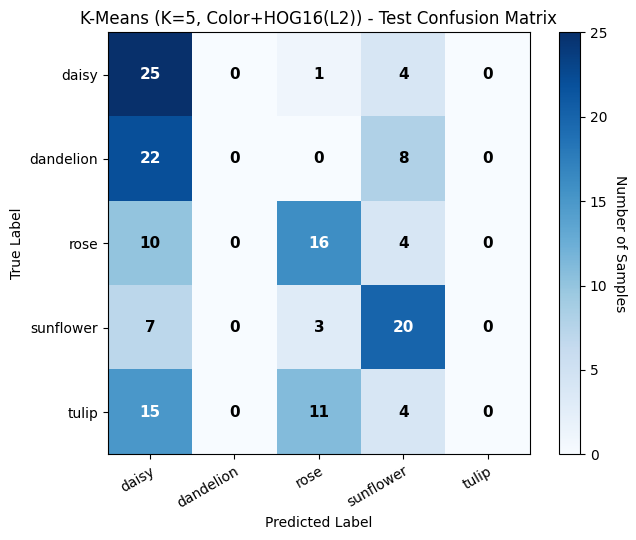

In [18]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_recall_fscore_support,
)

# 1) Pick best K-Means entry from km_results (highest validation accuracy)
best_km_name = max(km_results, key=lambda k: km_results[k]["val_acc"])
best_km_entry = km_results[best_km_name]
best_km_model = best_km_entry["model"]
best_km_mapping = best_km_entry["mapping"]
best_km_scaler = best_km_entry["scaler"]

# Map feature set name to its X_test array
test_km_map = {
    "Raw":             X_test_raw,
    "PCA":             X_test_pca,
    "HOG-8":           X_test_hog,
    "HOG-16":          X_test_hog16,
    "Color":           X_test_color,
    "Color+HOG16(L2)": fuse_l2_weighted(X_test_color, X_test_hog16, w_hog=0.8),
}

Xte_km = test_km_map[best_km_name]
if best_km_scaler is not None:
    Xte_km = best_km_scaler.transform(Xte_km)

# 2) Predict clusters on test set and map to class labels via train majority_map
test_clusters = best_km_model.predict(Xte_km)
y_test_pred_km = np.array([best_km_mapping[c] for c in test_clusters])

print(f"Selected K-Means Features: {best_km_name} (K={K})")
print(f"Test Accuracy (K-Means): {accuracy_score(y_test, y_test_pred_km):.4f}\n")

# 3) Precision, Recall, and F1-score per class
labels = np.unique(y_test)
precision, recall, f1, support = precision_recall_fscore_support(
    y_test, y_test_pred_km, labels=labels, zero_division=0
)
per_class_km_df = pd.DataFrame({
    "Class": labels,
    "Precision": np.round(precision, 4),
    "Recall": np.round(recall, 4),
    "F1-score": np.round(f1, 4),
    "Support": support,
})
print("Per-Class Metrics (Test - K-Means):")
print(per_class_km_df.to_string(index=False))

# 4) Confusion Matrix Heatmap on Test
cm_km = confusion_matrix(y_test, y_test_pred_km, labels=labels)
plot_cm_heatmap(
    cm_km,
    labels,
    f"K-Means (K={K}, {best_km_name}) - Test Confusion Matrix"
)

# download the Model

In [19]:
import joblib
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import normalize


def fuse_l2_weighted(color_feat, hog_feat, w_hog=0.8):
    return np.hstack([
        normalize(color_feat, norm="l2"),
        w_hog * normalize(hog_feat, norm="l2"),
    ])


w_hog = 0.8
Xtr_lr = fuse_l2_weighted(X_train_color, X_train_hog16, w_hog=w_hog)

lr_model = LogisticRegression(C=1.0, max_iter=5000, random_state=SEED)
lr_model.fit(Xtr_lr, y_train)

joblib_path = "best_flower_logistic_regression.joblib"
joblib.dump(
    {
        "model": lr_model,
        "w_hog": w_hog,
        "classes": lr_model.classes_,
    },
    joblib_path,
    compress=3,
)

from google.colab import files
files.download(joblib_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>